In [1]:
import pandas as pd

In [2]:
#Ler arquivos
df= pd.read_csv('Sales.csv')
df

,Sales Person,Country,Product,Date,Amount,Boxes Shipped
0,Jehu Rudeforth,UK,Mint Chip Choco,04/01/2022,"$5,320.00",180
1,Van Tuxwell,India,85% Dark Bars,01/08/2022,"$7,896.00",94
2,Gigi Bohling,India,Peanut Butter Cubes,07/07/2022,"$4,501.00",91
3,Jan Morforth,Australia,Peanut Butter Cubes,27/04/2022,"$12,726.00",342
4,Jehu Rudeforth,UK,Peanut Butter Cubes,24/02/2022,"$13,685.00",184
...,...,...,...,...,...,...
3277,Karlen McCaffrey,Australia,Spicy Special Slims,17/05/2024,"$5,303.58",354
3278,Jehu Rudeforth,USA,White Choc,07/06/2024,"$7,339.32",121
3279,Ches Bonnell,Canada,Organic Choco Syrup,26/07/2024,$616.09,238
3280,Dotty Strutley,India,Eclairs,28/07/2024,"$2,504.62",397


In [3]:
#ver tipos de dados de cada coluna
df.dtypes

Sales Person       str
Country            str
Product            str
Date               str
Amount             str
Boxes Shipped    int64
dtype: object

In [4]:
#"Object" quando n e identificado mas normalmente e str -> textual
# Limpar dados; converter coluna de datas

df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df

,Sales Person,Country,Product,Date,Amount,Boxes Shipped
0,Jehu Rudeforth,UK,Mint Chip Choco,2022-01-04,"$5,320.00",180
1,Van Tuxwell,India,85% Dark Bars,2022-08-01,"$7,896.00",94
2,Gigi Bohling,India,Peanut Butter Cubes,2022-07-07,"$4,501.00",91
3,Jan Morforth,Australia,Peanut Butter Cubes,2022-04-27,"$12,726.00",342
4,Jehu Rudeforth,UK,Peanut Butter Cubes,2022-02-24,"$13,685.00",184
...,...,...,...,...,...,...
3277,Karlen McCaffrey,Australia,Spicy Special Slims,2024-05-17,"$5,303.58",354
3278,Jehu Rudeforth,USA,White Choc,2024-06-07,"$7,339.32",121
3279,Ches Bonnell,Canada,Organic Choco Syrup,2024-07-26,$616.09,238
3280,Dotty Strutley,India,Eclairs,2024-07-28,"$2,504.62",397


In [ ]:
#remover simbolos e converter tipo
df['Amount'] = df['Amount'].str.removeprefix('$')
df['Amount'] = df['Amount'].str.replace(',', '')
df['Amount'] = df['Amount'].astype('float')
df

,Sales Person,Country,Product,Date,Amount,Boxes Shipped
0,Jehu Rudeforth,UK,Mint Chip Choco,2022-01-04,5320.00,180
1,Van Tuxwell,India,85% Dark Bars,2022-08-01,7896.00,94
2,Gigi Bohling,India,Peanut Butter Cubes,2022-07-07,4501.00,91
3,Jan Morforth,Australia,Peanut Butter Cubes,2022-04-27,12726.00,342
4,Jehu Rudeforth,UK,Peanut Butter Cubes,2022-02-24,13685.00,184
...,...,...,...,...,...,...
3277,Karlen McCaffrey,Australia,Spicy Special Slims,2024-05-17,5303.58,354
3278,Jehu Rudeforth,USA,White Choc,2024-06-07,7339.32,121
3279,Ches Bonnell,Canada,Organic Choco Syrup,2024-07-26,616.09,238
3280,Dotty Strutley,India,Eclairs,2024-07-28,2504.62,397


In [8]:
df.dtypes

Sales Person                str
Country                     str
Product                     str
Date             datetime64[us]
Amount                  float64
Boxes Shipped             int64
dtype: object

In [11]:
#Total de vendas

total_vendas = df['Amount'].sum()
print(f'$ {total_vendas:,.2f}')

$ 19,791,571.86


In [12]:
# Media de vendas

total_vendas = df['Amount'].mean()
print(f'$ {total_vendas:,.2f}')

$ 6,030.34


In [13]:
# Maior e menor venda

maior_venda = df['Amount'].max()
menor_venda = df['Amount'].min()

print(f'Maior venda: $ {maior_venda:,.2f}')
print(f'Menor venda: $ {menor_venda:,.2f}')

Maior venda: $ 26,170.95
Menor venda: $ 7.00


In [14]:
# Total de vendas por pais

vendas_por_pais = df.groupby('Country')['Amount'].sum()
vendas_por_pais

Country
Australia      3646444.35
Canada         3078495.65
India          3343730.83
New Zealand    3043654.04
UK             3365388.90
USA            3313858.09
Name: Amount, dtype: float64

In [15]:
#Ordenar de forma crescente

vendas_por_pais = vendas_por_pais.sort_values()
vendas_por_pais

Country
New Zealand    3043654.04
Canada         3078495.65
USA            3313858.09
India          3343730.83
UK             3365388.90
Australia      3646444.35
Name: Amount, dtype: float64

<Axes: ylabel='Country'>

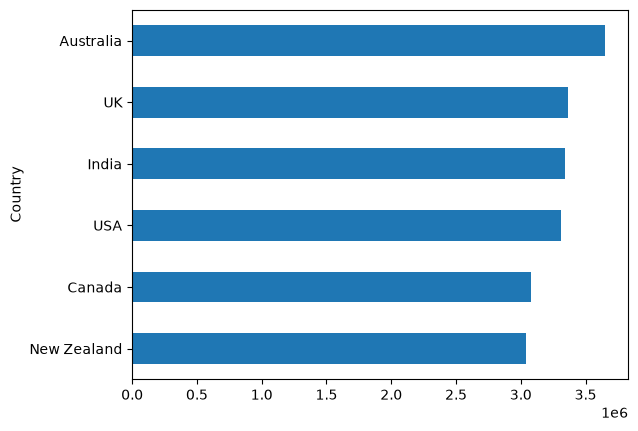

In [16]:
vendas_por_pais.plot.barh()

In [17]:
#Ticket medio por vendedor

ticket_medio = df.groupby('Sales Person')['Amount'].mean()
ticket_medio

Sales Person
Andria Kimpton         5540.297521
Barr Faughny           6440.518682
Beverie Moffet         5949.475800
Brien Boise            6272.493585
Camilla Castle         6548.053437
Ches Bonnell           7101.388611
Curtice Advani         5013.028406
Dennison Crosswaite    6339.112721
Dotty Strutley         5630.566389
Gigi Bohling           5264.514255
Gunar Cockshoot        5909.173876
Husein Augar           5755.699386
Jan Morforth           6039.192308
Jehu Rudeforth         5492.287054
Kaine Padly            6289.353778
Karlen McCaffrey       5062.642837
Kelci Walkden          6190.920370
Madelene Upcott        7481.694222
Mallorie Waber         5226.856341
Marney O'Breen         6195.760222
Oby Sorrel             6919.755918
Rafaelita Blaksland    6557.504412
Roddy Speechley        6266.353333
Van Tuxwell            6368.791438
Wilone O'Kielt         4313.352157
Name: Amount, dtype: float64

In [18]:
ticket_medio = ticket_medio.sort_values()
ticket_medio

Sales Person
Wilone O'Kielt         4313.352157
Curtice Advani         5013.028406
Karlen McCaffrey       5062.642837
Mallorie Waber         5226.856341
Gigi Bohling           5264.514255
Jehu Rudeforth         5492.287054
Andria Kimpton         5540.297521
Dotty Strutley         5630.566389
Husein Augar           5755.699386
Gunar Cockshoot        5909.173876
Beverie Moffet         5949.475800
Jan Morforth           6039.192308
Kelci Walkden          6190.920370
Marney O'Breen         6195.760222
Roddy Speechley        6266.353333
Brien Boise            6272.493585
Kaine Padly            6289.353778
Dennison Crosswaite    6339.112721
Van Tuxwell            6368.791438
Barr Faughny           6440.518682
Camilla Castle         6548.053437
Rafaelita Blaksland    6557.504412
Oby Sorrel             6919.755918
Ches Bonnell           7101.388611
Madelene Upcott        7481.694222
Name: Amount, dtype: float64

In [19]:
# Grafico top 10

top_10 = ticket_medio.tail(10)
top_10

Sales Person
Brien Boise            6272.493585
Kaine Padly            6289.353778
Dennison Crosswaite    6339.112721
Van Tuxwell            6368.791438
Barr Faughny           6440.518682
Camilla Castle         6548.053437
Rafaelita Blaksland    6557.504412
Oby Sorrel             6919.755918
Ches Bonnell           7101.388611
Madelene Upcott        7481.694222
Name: Amount, dtype: float64

<Axes: ylabel='Sales Person'>

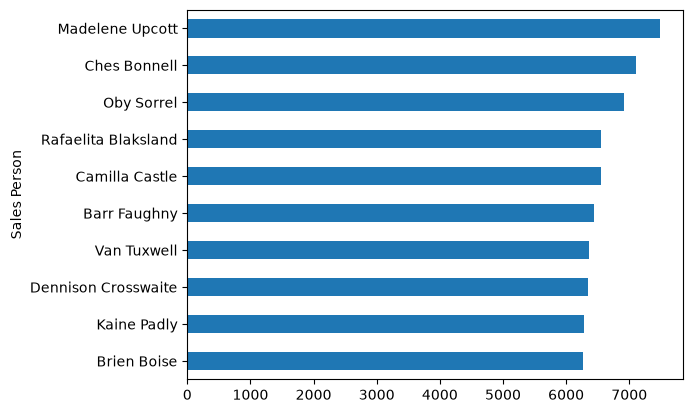

In [20]:
top_10.plot.barh()

<Axes: ylabel='Product'>

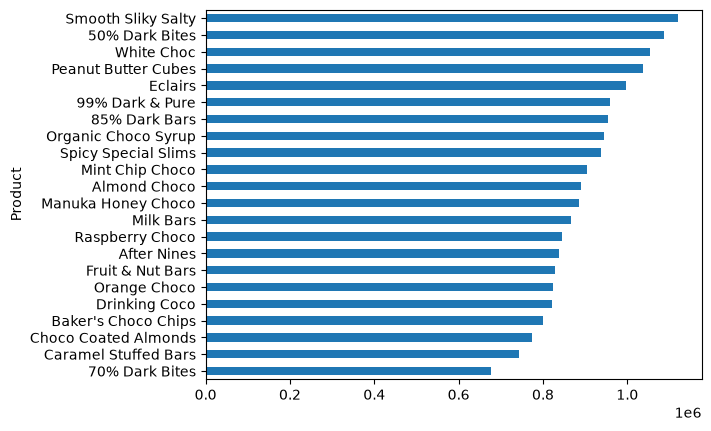

In [21]:
# Analise por produtos

vendas_por_produto = df.groupby('Product')['Amount'].sum()
vendas_por_produto = vendas_por_produto.sort_values()
vendas_por_produto.plot.barh()

In [22]:
# vendas por ano

vendas_por_ano = df.groupby(df['Date'].dt.year)['Amount'].sum()
vendas_por_ano

Date
2022    6183625.00
2023    6643377.96
2024    6964568.90
Name: Amount, dtype: float64

<Axes: >

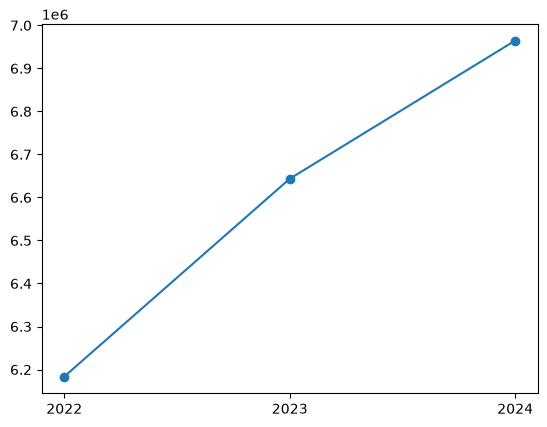

In [ ]:
# Grafico de linha para valores temporais

vendas_por_ano.plot.line(marker='o', xlabel='', xticks=vendas_por_ano.index)

In [24]:
# Media de vendas por mes

vendas_mes = df.groupby(df['Date'].dt.month)['Amount'].mean()
vendas_mes

Date
1    6209.334610
2    6763.930000
3    6119.005827
4    6107.139040
5    5964.816222
6    5672.662454
7    5743.920112
8    5887.689204
Name: Amount, dtype: float64

<Axes: >

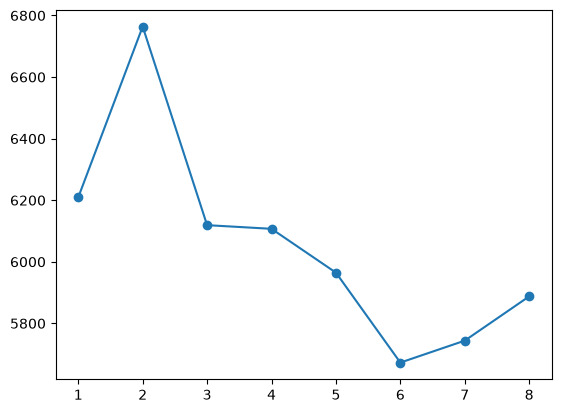

In [25]:
vendas_mes.plot.line(marker='o', xlabel='')

In [26]:
# Venda por mes

vendas_mes = df.groupby([df['Date'].dt.year, df['Date'].dt.month])['Amount'].sum()
vendas_mes

Date  Date
2022  1        896105.00
      2        699377.00
      3        749483.00
      4        674051.00
      5        752892.00
      6        865144.00
      7        803425.00
      8        743148.00
2023  1        958985.77
      2        749617.46
      3        807494.33
      4        727743.72
      5        811951.78
      6        932625.17
      7        861856.66
      8        793103.07
2024  1       1013621.82
      2        783102.44
      3        847791.96
      4        760132.50
      5        850906.79
      6        976162.77
      7        902250.63
      8        830599.99
Name: Amount, dtype: float64

<Axes: >

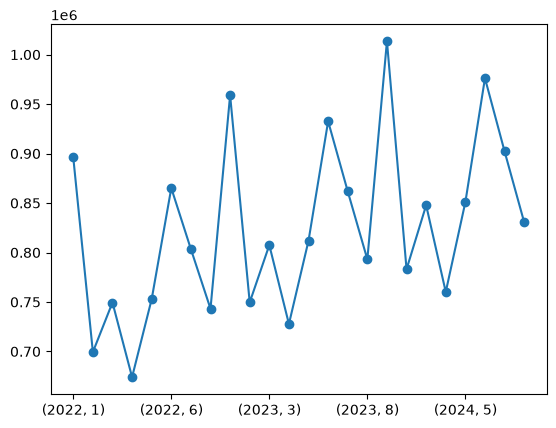

In [27]:
vendas_mes.plot.line(marker='o', xlabel='')